DATA CLEANING 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
import warnings
warnings.filterwarnings('ignore')

print("Libraries loaded successfully")

Libraries loaded successfully


Load both files

In [13]:
# skiprows=[1] removes the units row (kW, kWh, %) which is not data
orig = pd.read_csv('../data/raw/original_load.csv', skiprows=[1])
more = pd.read_csv('../data/raw/10_percent_more_load.csv', skiprows=[1])

print("Original load shape:", orig.shape)
print("10% more load shape:", more.shape)

Original load shape: (8760, 7)
10% more load shape: (8760, 7)


Data quality check

In [14]:

for name, df in [("Baseline (650kW)", orig), ("+10% Load (760kW)", more)]:
    print(f"\n--- {name} ---")
    print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")
    print(f"Nulls: {df.isnull().sum().sum()} total")
    print(f"Duplicates: {df.duplicated().sum()}")
    print("Columns:", df.columns.tolist())


--- Baseline (650kW) ---
Shape: 8760 rows x 7 columns
Nulls: 0 total
Duplicates: 0
Columns: ['Time', 'Solar Power Output', 'Generator Power Output', 'Total Electrical Load Served', 'Excess Electrical Production', 'Li-Ion battery Energy Content', 'Li-Ion battery State of Charge']

--- +10% Load (760kW) ---
Shape: 8760 rows x 7 columns
Nulls: 0 total
Duplicates: 0
Columns: ['Time', 'Solar Power Output', 'Generator Power Output', 'Total Electrical Load Served', 'Excess Electrical Production', 'Li-Ion bATTERY Energy Content', 'Li-Ion battery State of Charge']


 Clean column names and fix data types

In [15]:
# Standardised column names for both files
clean_cols = ['datetime', 'solar_kw', 'generator_kw',
              'load_kw', 'excess_kw', 'battery_kwh', 'battery_soc']

orig.columns = clean_cols
more.columns = clean_cols

# Fix datetime
orig['datetime'] = pd.to_datetime(orig['datetime'], format='%m/%d/%Y %H:%M')
more['datetime'] = pd.to_datetime(more['datetime'], format='%m/%d/%Y %H:%M')

# Fix all numeric columns
for col in clean_cols[1:]:
    orig[col] = pd.to_numeric(orig[col], errors='coerce')
    more[col] = pd.to_numeric(more[col], errors='coerce')

# Verify
print("Orig dtypes after fix:")
print(orig.dtypes)
print()
print("Date range:", orig['datetime'].min(), "to", orig['datetime'].max())
print("Total hours:", len(orig))

Orig dtypes after fix:
datetime        datetime64[us]
solar_kw               float64
generator_kw           float64
load_kw                float64
excess_kw              float64
battery_kwh            float64
battery_soc            float64
dtype: object

Date range: 2007-01-01 00:00:00 to 2007-12-31 23:00:00
Total hours: 8760


FEATURE ENGINEERING

Adding date dimension columns

In [16]:
for df in [orig, more]:
    df['hour']       = df['datetime'].dt.hour
    df['day']        = df['datetime'].dt.day
    df['month']      = df['datetime'].dt.month
    df['month_name'] = df['datetime'].dt.strftime('%B')
    df['year']       = df['datetime'].dt.year
    df['weekday']    = df['datetime'].dt.day_name()
    df['is_weekend'] = df['datetime'].dt.dayofweek >= 5
    df['season']     = df['month'].apply(lambda m:
        'Winter' if m in [12, 1, 2] else
        'Spring' if m in [3, 4, 5] else
        'Summer' if m in [6, 7, 8] else 'Autumn')
    df['is_daytime'] = (df['hour'] >= 6) & (df['hour'] <= 18)

print("Date dimensions added successfully")
print("New columns:", ['hour','day','month','month_name','year',
      'weekday','is_weekend','season','is_daytime'])

Date dimensions added successfully
New columns: ['hour', 'day', 'month', 'month_name', 'year', 'weekday', 'is_weekend', 'season', 'is_daytime']


 Adding KPI columns

In [17]:
for df in [orig, more]:
    # Total generation per hour
    df['total_gen_kw'] = df['solar_kw'] + df['generator_kw']

    # Renewable penetration per hour
    df['renewable_pct'] = df['solar_kw'] / df['load_kw'].replace(0, None) * 100

    # Generator dependency per hour
    df['gen_dep_pct'] = df['generator_kw'] / df['load_kw'].replace(0, None) * 100

    # Excess generation rate per hour
    df['excess_rate_pct'] = df['excess_kw'] / df['total_gen_kw'].replace(0, None) * 100

    # Generator running flag
    df['generator_on'] = (df['generator_kw'] > 0).astype(int)

    # Solar covering full load flag
    df['solar_covers_load'] = (df['solar_kw'] >= df['load_kw']).astype(int)

    # Battery charging flag (SOC increasing)
    df['battery_charging'] = (df['battery_soc'].diff() > 0).astype(int)

    # CO2 saved vs all-generator scenario (natural gas: 0.45 kg CO2/kWh)
    df['co2_saved_kg'] = df['solar_kw'] * 0.45

print("KPI columns added")
print("New KPI columns:", ['total_gen_kw','renewable_pct','gen_dep_pct',
      'excess_rate_pct','generator_on','solar_covers_load',
      'battery_charging','co2_saved_kg'])

KPI columns added
New KPI columns: ['total_gen_kw', 'renewable_pct', 'gen_dep_pct', 'excess_rate_pct', 'generator_on', 'solar_covers_load', 'battery_charging', 'co2_saved_kg']


Adding scenario label and combining into one file

In [18]:
orig['scenario'] = 'Baseline (650 kW)'
more['scenario'] = '+10% Load (760 kW)'

# Combining both into one DataFrame for SQL and Tableau
combined = pd.concat([orig, more], ignore_index=True)

print("Combined shape:", combined.shape)
print("Scenarios:", combined['scenario'].unique().tolist())
print("Total rows:", len(combined))

Combined shape: (17520, 25)
Scenarios: ['Baseline (650 kW)', '+10% Load (760 kW)']
Total rows: 17520


Printing all key metrics

In [19]:

print("ENERGY MIX KPI SUMMARY")

for scenario, df in [("Baseline (650 kW)", orig), ("+10% Load (760 kW)", more)]:
    solar_ann   = df['solar_kw'].sum()
    gen_ann     = df['generator_kw'].sum()
    load_ann    = df['load_kw'].sum()
    excess_ann  = df['excess_kw'].sum()
    total_gen   = solar_ann + gen_ann
    gen_hours   = df['generator_on'].sum()
    co2_saved   = df['co2_saved_kg'].sum() / 1000  # tonnes

    print(f"\n{scenario}")
    print(f"  Total load served:        {load_ann/1000:.1f} MWh")
    print(f"  Solar generation:         {solar_ann/1000:.1f} MWh")
    print(f"  Generator output:         {gen_ann/1000:.1f} MWh")
    print(f"  Excess generation:        {excess_ann/1000:.1f} MWh")
    print(f"  Renewable penetration:    {solar_ann/load_ann*100:.2f}%")
    print(f"  Generator dependency:     {gen_ann/load_ann*100:.2f}%")
    print(f"  Excess generation rate:   {excess_ann/total_gen*100:.2f}%")
    print(f"  Generator hours per year: {gen_hours} of 8,760")
    print(f"  Battery SOC mean:         {df['battery_soc'].mean():.2f}%")
    print(f"  Battery SOC minimum:      {df['battery_soc'].min():.2f}%")
    print(f"  CO2 saved vs all-gen:     {co2_saved:.1f} tonnes")

ENERGY MIX KPI SUMMARY

Baseline (650 kW)
  Total load served:        401.5 MWh
  Solar generation:         641.1 MWh
  Generator output:         48.9 MWh
  Excess generation:        263.5 MWh
  Renewable penetration:    159.67%
  Generator dependency:     12.18%
  Excess generation rate:   38.18%
  Generator hours per year: 555 of 8,760
  Battery SOC mean:         80.00%
  Battery SOC minimum:      20.21%
  CO2 saved vs all-gen:     288.5 tonnes

+10% Load (760 kW)
  Total load served:        441.6 MWh
  Solar generation:         641.1 MWh
  Generator output:         67.3 MWh
  Excess generation:        239.5 MWh
  Renewable penetration:    145.15%
  Generator dependency:     15.23%
  Excess generation rate:   33.82%
  Generator hours per year: 716 of 8,760
  Battery SOC mean:         80.15%
  Battery SOC minimum:      20.13%
  CO2 saved vs all-gen:     288.5 tonnes


Save clean files

In [20]:
orig.to_csv('../data/clean/clean_baseline.csv', index=False)
more.to_csv('../data/clean/clean_more_load.csv', index=False)
combined.to_csv('../data/clean/clean_combined.csv', index=False)

print("3 clean files saved:")
print(f"  clean_baseline.csv  — {len(orig):,} rows")
print(f"  clean_more_load.csv — {len(more):,} rows")
print(f"  clean_combined.csv  — {len(combined):,} rows (both scenarios)")

3 clean files saved:
  clean_baseline.csv  — 8,760 rows
  clean_more_load.csv — 8,760 rows
  clean_combined.csv  — 17,520 rows (both scenarios)


 EDA CHARTS

Chart 1: Monthly Energy Mix Stacked Bar

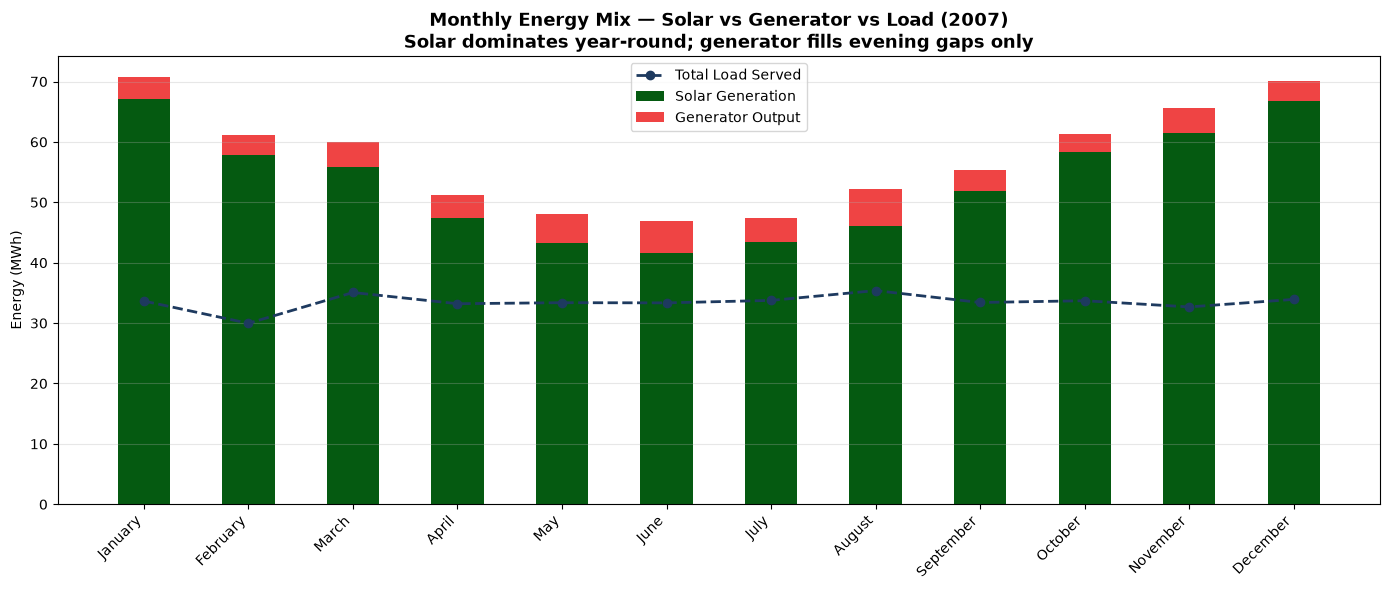

In [23]:
monthly = orig.groupby(['month', 'month_name']).agg(
    solar_mwh=('solar_kw',    lambda x: x.sum() / 1000),
    gen_mwh=('generator_kw',  lambda x: x.sum() / 1000),
    load_mwh=('load_kw',      lambda x: x.sum() / 1000),
    excess_mwh=('excess_kw',  lambda x: x.sum() / 1000),
).reset_index().sort_values('month')

fig, ax = plt.subplots(figsize=(14, 6))
x = range(len(monthly))
width = 0.5

bars1 = ax.bar(x, monthly['solar_mwh'],  width, label='Solar Generation', color="#055A11")
bars2 = ax.bar(x, monthly['gen_mwh'],    width, bottom=monthly['solar_mwh'],
               label='Generator Output', color='#EF4444')

# Overlay load line
ax.plot(x, monthly['load_mwh'], 'o--', color='#1E3A5F',
        linewidth=2, markersize=6, label='Total Load Served', zorder=5)

ax.set_xticks(list(x))
ax.set_xticklabels(monthly['month_name'], rotation=45, ha='right')
ax.set_title("Monthly Energy Mix — Solar vs Generator vs Load (2007)\nSolar dominates year-round; generator fills evening gaps only",
             fontsize=13, fontweight='bold')
ax.set_ylabel("Energy (MWh)")
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('../reports/chart1_monthly_energy_mix.png', dpi=150, bbox_inches='tight')
plt.show()

Chart 2: 24-Hour Load and Generation Profile

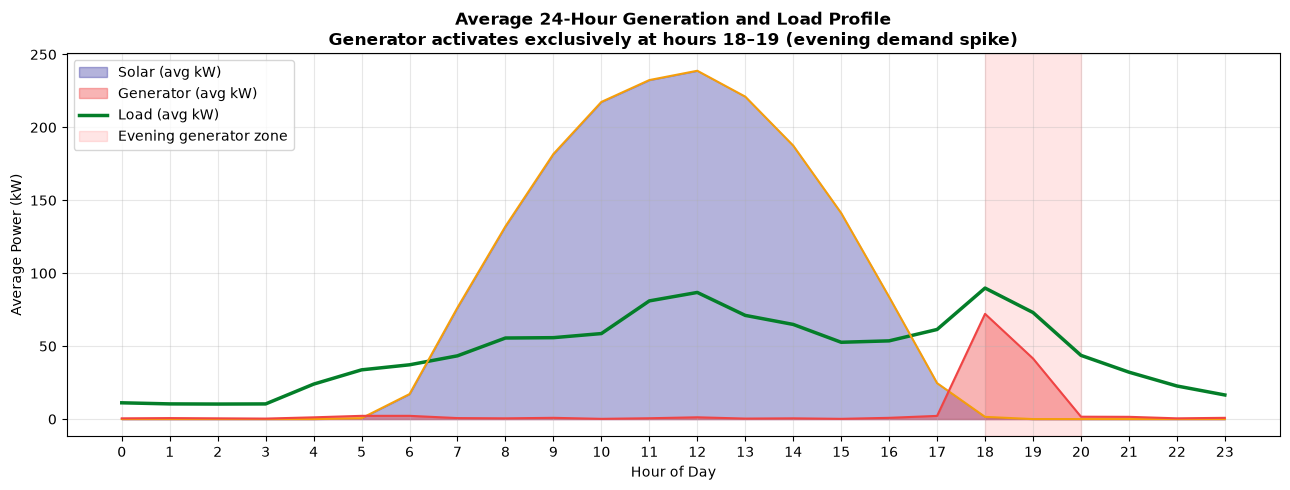

In [24]:
hourly = orig.groupby('hour').agg(
    avg_load=('load_kw',      'mean'),
    avg_solar=('solar_kw',    'mean'),
    avg_gen=('generator_kw',  'mean'),
    avg_excess=('excess_kw',  'mean')
).reset_index()

fig, ax = plt.subplots(figsize=(13, 5))
ax.fill_between(hourly['hour'], hourly['avg_solar'], alpha=0.3,
                color="#07058A", label='Solar (avg kW)')
ax.fill_between(hourly['hour'], hourly['avg_gen'],   alpha=0.4,
                color='#EF4444', label='Generator (avg kW)')
ax.plot(hourly['hour'], hourly['avg_load'],   color="#047E29",
        linewidth=2.5, label='Load (avg kW)')
ax.plot(hourly['hour'], hourly['avg_solar'],  color='#F59E0B',
        linewidth=1.5)
ax.plot(hourly['hour'], hourly['avg_gen'],    color='#EF4444',
        linewidth=1.5)

ax.axvspan(18, 20, alpha=0.1, color='red', label='Evening generator zone')
ax.set_xticks(range(0, 24))
ax.set_title("Average 24-Hour Generation and Load Profile\nGenerator activates exclusively at hours 18–19 (evening demand spike)",
             fontsize=12, fontweight='bold')
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Average Power (kW)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../reports/chart2_hourly_profile.png', dpi=150, bbox_inches='tight')
plt.show()

Chart 3: Battery SOC Heatmap by Hour and Month

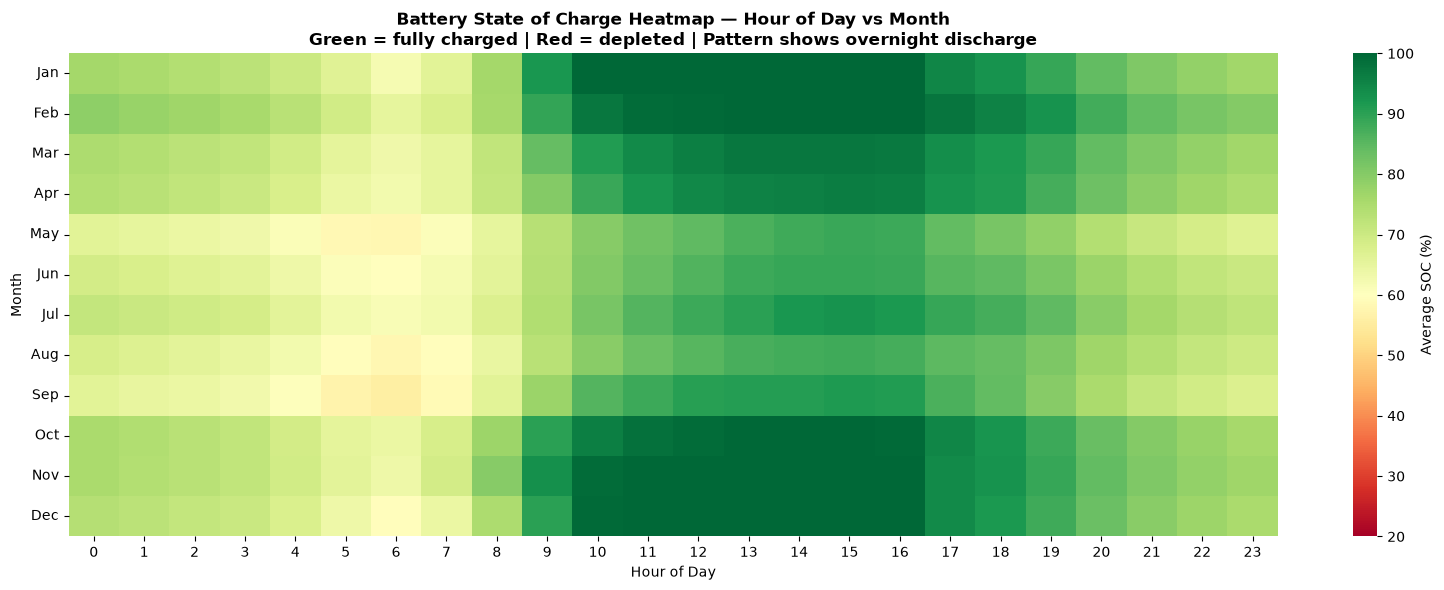

In [25]:
soc_pivot = orig.pivot_table(
    values='battery_soc',
    index='month',
    columns='hour',
    aggfunc='mean'
)

fig, ax = plt.subplots(figsize=(16, 6))
sns.heatmap(soc_pivot, cmap='RdYlGn', vmin=20, vmax=100,
            ax=ax, cbar_kws={'label': 'Average SOC (%)'})

month_names = ['Jan','Feb','Mar','Apr','May','Jun',
               'Jul','Aug','Sep','Oct','Nov','Dec']
ax.set_yticklabels(month_names, rotation=0)
ax.set_title("Battery State of Charge Heatmap — Hour of Day vs Month\nGreen = fully charged | Red = depleted | Pattern shows overnight discharge",
             fontsize=12, fontweight='bold')
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Month")
plt.tight_layout()
plt.savefig('../reports/chart3_soc_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

Chart 4: Renewable Penetration by Month

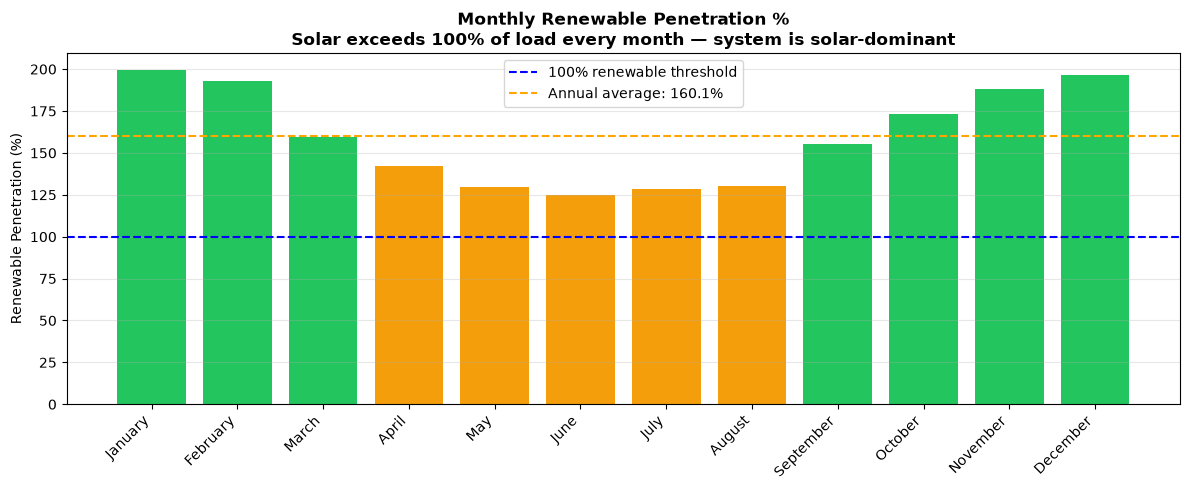

In [26]:
monthly_re = orig.groupby(['month', 'month_name']).apply(
    lambda x: x['solar_kw'].sum() / x['load_kw'].sum() * 100
).reset_index(name='renewable_pct').sort_values('month')

fig, ax = plt.subplots(figsize=(12, 5))
colors = ['#22C55E' if v >= 150 else '#F59E0B' if v >= 120 else '#EF4444'
          for v in monthly_re['renewable_pct']]
bars = ax.bar(range(12), monthly_re['renewable_pct'], color=colors)
ax.axhline(100, color='blue', linestyle='--', linewidth=1.5,
           label='100% renewable threshold')
ax.axhline(monthly_re['renewable_pct'].mean(), color='orange',
           linestyle='--', linewidth=1.5,
           label=f"Annual average: {monthly_re['renewable_pct'].mean():.1f}%")

ax.set_xticks(range(12))
ax.set_xticklabels(monthly_re['month_name'], rotation=45, ha='right')
ax.set_title("Monthly Renewable Penetration %\nSolar exceeds 100% of load every month — system is solar-dominant",
             fontsize=12, fontweight='bold')
ax.set_ylabel("Renewable Penetration (%)")
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('../reports/chart4_renewable_penetration.png', dpi=150, bbox_inches='tight')
plt.show()

Chart 5: Scenario Comparison; Baseline vs +10% Load

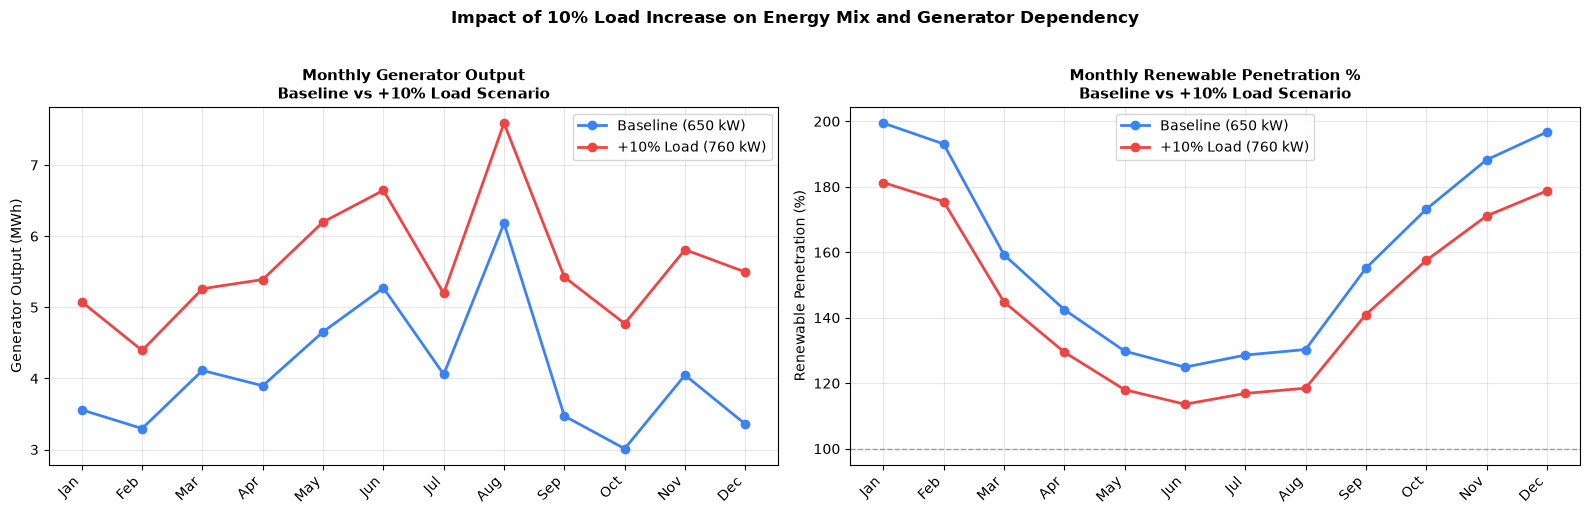

In [27]:
monthly_comp = combined.groupby(['month', 'month_name', 'scenario']).agg(
    solar_mwh=('solar_kw',     lambda x: x.sum()/1000),
    gen_mwh=('generator_kw',   lambda x: x.sum()/1000),
    load_mwh=('load_kw',       lambda x: x.sum()/1000),
    renewable_pct=('solar_kw', lambda x: x.sum()/combined.loc[x.index,'load_kw'].sum()*100)
).reset_index().sort_values(['month','scenario'])

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Generator output comparison
for scenario, color in [('Baseline (650 kW)', '#3B82F6'),
                         ('+10% Load (760 kW)', '#EF4444')]:
    sub = monthly_comp[monthly_comp['scenario']==scenario].sort_values('month')
    axes[0].plot(range(12), sub['gen_mwh'], marker='o',
                 label=scenario, color=color, linewidth=2)

axes[0].set_xticks(range(12))
axes[0].set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun',
                          'Jul','Aug','Sep','Oct','Nov','Dec'],
                         rotation=45, ha='right')
axes[0].set_title("Monthly Generator Output\nBaseline vs +10% Load Scenario",
                  fontsize=11, fontweight='bold')
axes[0].set_ylabel("Generator Output (MWh)")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Renewable penetration comparison
for scenario, color in [('Baseline (650 kW)', '#3B82F6'),
                         ('+10% Load (760 kW)', '#EF4444')]:
    sub = combined[combined['scenario']==scenario].groupby('month').apply(
        lambda x: x['solar_kw'].sum()/x['load_kw'].sum()*100
    ).reset_index(name='re_pct')
    axes[1].plot(range(12), sub['re_pct'], marker='o',
                 label=scenario, color=color, linewidth=2)

axes[1].axhline(100, color='gray', linestyle='--', linewidth=1, alpha=0.7)
axes[1].set_xticks(range(12))
axes[1].set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun',
                          'Jul','Aug','Sep','Oct','Nov','Dec'],
                         rotation=45, ha='right')
axes[1].set_title("Monthly Renewable Penetration %\nBaseline vs +10% Load Scenario",
                  fontsize=11, fontweight='bold')
axes[1].set_ylabel("Renewable Penetration (%)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle("Impact of 10% Load Increase on Energy Mix and Generator Dependency",
             fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../reports/chart5_scenario_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

Export to SQLite

In [28]:
conn = sqlite3.connect('../sql/energy_mix.db')

orig.to_sql('baseline', conn, if_exists='replace', index=False)
more.to_sql('more_load', conn, if_exists='replace', index=False)
combined.to_sql('combined', conn, if_exists='replace', index=False)

conn.close()
print("Database created: ../sql/energy_mix.db")
print("Tables: baseline, more_load, combined")

Database created: ../sql/energy_mix.db
Tables: baseline, more_load, combined
